# 07 — Host galaxies, and galaxies alone

Supernovae explode in galaxies. Their **host** adds light (and photon noise) under the
supernova, and it is often a science target itself. `slicersim` models a host as a
**spectrum × image**, rendered on the spaxels of each Lazuli field and convolved by the PSF.

In this notebook:
1. a supernova in its host, and how a host model is named,
2. changing the host properties,
3. the redshift: the supernova and its host move together,
4. the host as a source of noise,
5. a galaxy alone, with `LazuliGalaxy`.

*Requires `slicersim >= 1.4.2`.*

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os
MOUNT = "~/s3/schmidt-observatory-system"
os.environ['SNCOSMO_DATA_DIR'] = os.path.expanduser(f"{MOUNT}/nov26-symposium/sncosmo_data_dir/")

import numpy as np
import matplotlib.pyplot as plt
import slicersim

SKY = ["background", "thermal"]   # switched off in the images, to see the sources only

***
## 1. A supernova in its host

Any target accepts a `host`. Here, a SN Ia at $z=0.9$ in **NGC 0628** (M 74), a nearby spiral
galaxy whose image and spectrum are moved to $z=0.9$. Positions are in spaxels of the current
field (narrow, 40 mas), from the field center.

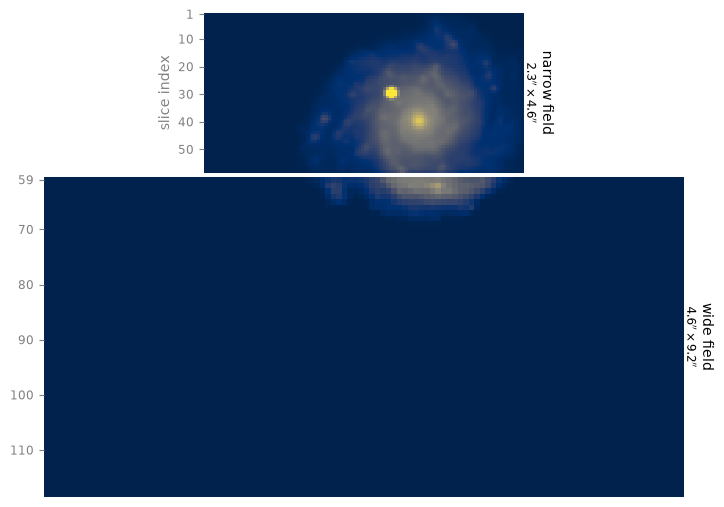

In [2]:
sn = slicersim.LazuliSupernova(redshift=0.9, host="ngc0628")
sn.change_properties(pointsource__position=(10, 0), host__position=(20, -10))

(cube_narrow, _), (cube_wide, _) = sn.get_cube(which="both", switch_off=SKY)
fig = sn.show_cube((cube_narrow, cube_wide), lbda_range=[4000 * 1.9, 7000 * 1.9])  # rest-frame 4000-7000 Å

`show_cube()` displays both fields following the Lazuli layout: the wide field lies right
below the narrow one, so it only sees the outskirts of the galaxy.

### Host model names

A host model is named `"spatial:spectral"`:

| part | name | model |
|---|---|---|
| spatial | `sersic` | analytic Sersic profile (`r_kpc`, `n`, `ellip`, `theta`) |
| spatial | `ngcXXXX`, e.g. `ngc0628` | r-band image of that NGC galaxy (`rotation`) |
| spectral | `bb`, `blackbody` or `bb-<T>`, e.g. `bb-5000` | blackbody of temperature T [K] |
| spectral | `ngcXXXX`, e.g. `ngc0628` | spectral template of that NGC galaxy |

A bare NGC name, `"ngc0628"`, means `"ngc0628:ngc0628"`. Parts can be mixed, e.g.
`"sersic:ngc0628"`. Each model comes with default parameters:

In [3]:
from slicersim.scene.host import get_host_config

print(get_host_config("sersic:bb-5000"))
print(get_host_config("ngc0628"))

{'refmodel': 'sersic:bb-5000', 'redshift': 0.1, 'r_kpc': 5, 'n': 2, 'ellip': 0.3, 'theta': -30, 'magabs': -21, 'band': 'sdssr'}
{'refmodel': 'ngc0628:ngc0628', 'redshift': 0.1, 'magabs': -21, 'band': 'sdssr'}


- `magabs` is the **rest-frame** absolute magnitude in `band` (K-corrected, as the SN `MBmax`):
  the host luminosity does not depend on the redshift. `mag` would set the observed magnitude
  instead.
- `r_kpc` is the effective radius of the Sersic profile, in kpc.

To change these defaults when building the target, give the host as a dict, the model name
being `"refmodel"`:

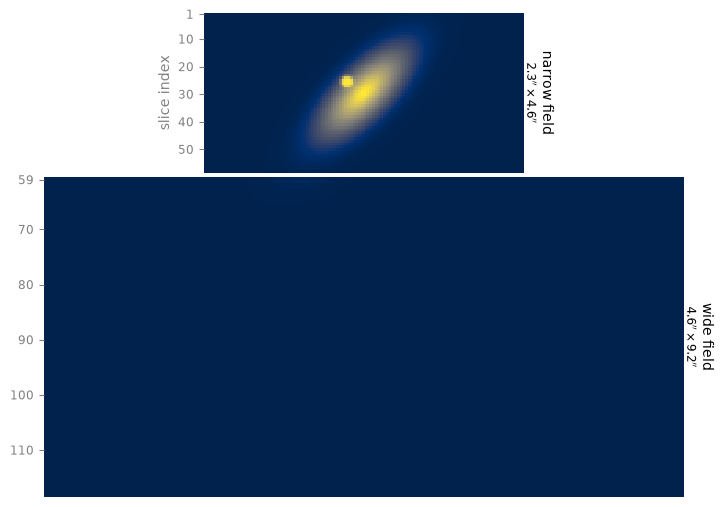

In [4]:
sn_disk = slicersim.LazuliSupernova(redshift=0.9,
                                    host={"refmodel": "sersic:bb-6000", "r_kpc": 3, "n": 1,
                                          "ellip": 0.6, "theta": 45, "magabs": -21.5,
                                          "position": (0, 0)})
sn_disk.change_properties(pointsource__position=(-6, 4))

(cube_narrow, _), (cube_wide, _) = sn_disk.get_cube(which="both", switch_off=SKY)
fig = sn_disk.show_cube((cube_narrow, cube_wide), lbda_range=[4000 * 1.9, 7000 * 1.9])

***
## 2. Changing the host properties

Host parameters are changed like any other property, with the `host__` prefix. Use
`pointsource__` for the supernova: `position` exists for both, so the short name `position`
is ambiguous (and ignored, with a warning).

In [5]:
sn_disk.simulation.scene.host.mutable_parameters

['r_kpc',
 'redshift',
 'cosmology',
 'r_eff',
 'n',
 'ellip',
 'theta',
 'flux',
 'pixel_scale',
 'shape',
 'position',
 'oversample',
 'temperature',
 'mag',
 'magabs',
 'band',
 'magsys']

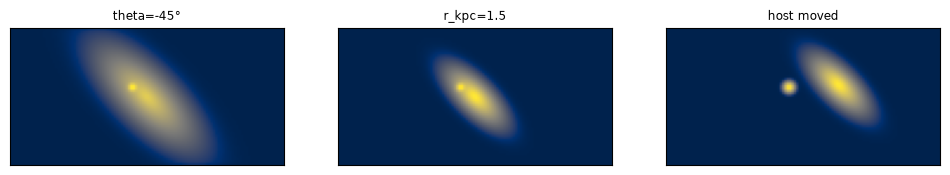

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (label, change) in zip(axes, {"theta=-45°": dict(host__theta=-45),
                                     "r_kpc=1.5": dict(host__r_kpc=1.5),
                                     "host moved": dict(host__position=(15, 5))}.items()):
    sn_disk.change_properties(**change)
    cube, _ = sn_disk.get_cube(which="narrow", switch_off=SKY)
    ax.imshow(cube.sum(axis=0), origin="lower", cmap="cividis", norm="asinh")
    ax.set_title(label, fontsize="small"); ax.set_xticks([]); ax.set_yticks([])

***
## 3. The redshift: the supernova and its host move together

`redshift` is shared by the supernova and its host. Changing it moves the whole system:
both spectra are redshifted and dimmed the same way, and the host keeps its physical size, so
its angular size shrinks with the angular diameter distance.

z=0.3: SN z=0.3, host z=0.3


z=0.9: SN z=0.9, host z=0.9


z=1.5: SN z=1.5, host z=1.5


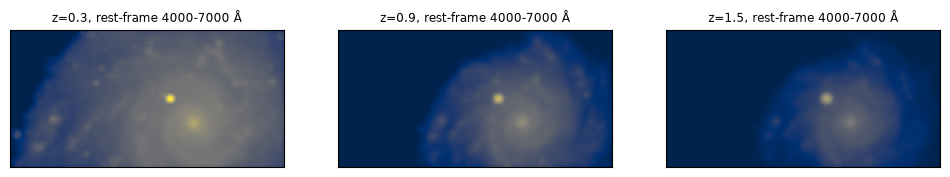

In [7]:
redshifts = [0.3, 0.9, 1.5]
images = []
for z in redshifts:
    sn.change_properties(redshift=z)
    cube, _ = sn.get_cube(which="narrow", switch_off=SKY)
    lbda = sn.simulation.spectrograph.lbda
    restframe = (lbda > 4000 * (1 + z)) & (lbda < 7000 * (1 + z))
    images.append(cube[restframe].sum(axis=0))
    print(f"z={z}: SN z={sn.get_properties('pointsource__redshift', as_dict=False)}, "
          f"host z={sn.get_properties('host__redshift', as_dict=False)}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, z, image in zip(axes, redshifts, images):
    ax.imshow(image, origin="lower", cmap="cividis", norm="asinh", vmin=0, vmax=images[0].max())
    ax.set_title(f"z={z}, rest-frame 4000-7000 Å", fontsize="small"); ax.set_xticks([]); ax.set_yticks([])

sn.change_properties(redshift=0.9)

***
## 4. The host as a source of noise

The host light under the supernova adds photon noise: it is the `host` variance source
(notebook 05). How much depends on where the supernova sits. With a fixed readout:

In [8]:
snr_range = dict(lbda_range=[4000, 7000], frame="rest")

for label, host, position in [("no host", None, (0, 0)),
                              ("on the core", "ngc0628", (0, 0)),
                              ("0.2\" from the core", "ngc0628", (5, 0)),
                              ("0.5\" from the core", "ngc0628", (12, 0))]:
    target = slicersim.LazuliSupernova(redshift=1.0, host=host)
    target.change_properties(pointsource__position=position)    # the host is at (0, 0)
    target.change_detector(nmd=(47, 8, 0), nramps=1)
    budget = target.simulation.get_band_variance_contribution(**snr_range)
    print(f"{label:>20s}: SNR per wavelength bin={budget['snr']:.2f}, host share of the variance: {budget['frac_host']:.1%}")

             no host: SNR per wavelength bin=6.52, host share of the variance: 0.0%


         on the core: SNR per wavelength bin=6.27, host share of the variance: 7.7%


  0.2" from the core: SNR per wavelength bin=6.45, host share of the variance: 2.3%


  0.5" from the core: SNR per wavelength bin=6.49, host share of the variance: 1.0%


For a typical galaxy ($M_r=-21$) the host contributes only a few percent of the variance: the
Lazuli PSF is small, so little host light falls under the supernova. Brighter or more compact
hosts matter more (see exercise 6).

`show_variance_sources()` includes the host:

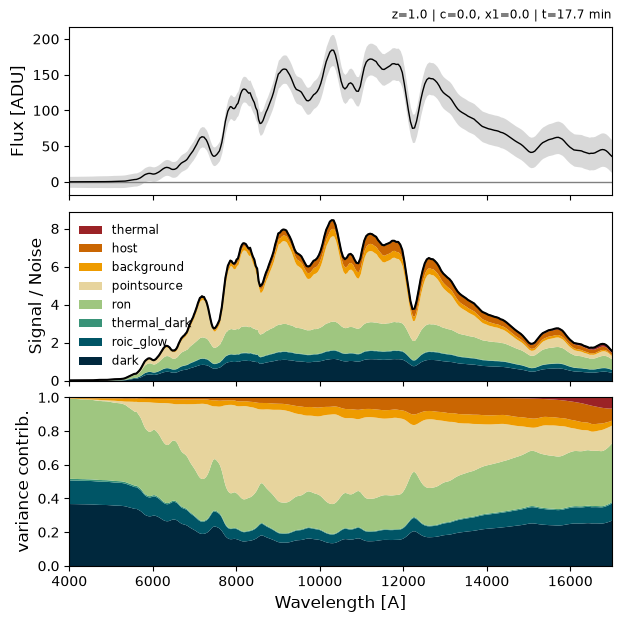

In [9]:
target = slicersim.LazuliSupernova(redshift=1.0, host="ngc0628")
_ = target.setup_to_snr(10, **snr_range)
fig = target.simulation.show_variance_sources(flux_calibrated=False)

***
## 5. A galaxy alone: `LazuliGalaxy`

`LazuliGalaxy` observes a galaxy without any point source on top of it. It uses the same model
names (`model`) and parameters as a host; there is no point source, so the parameters can be
changed by their short names.

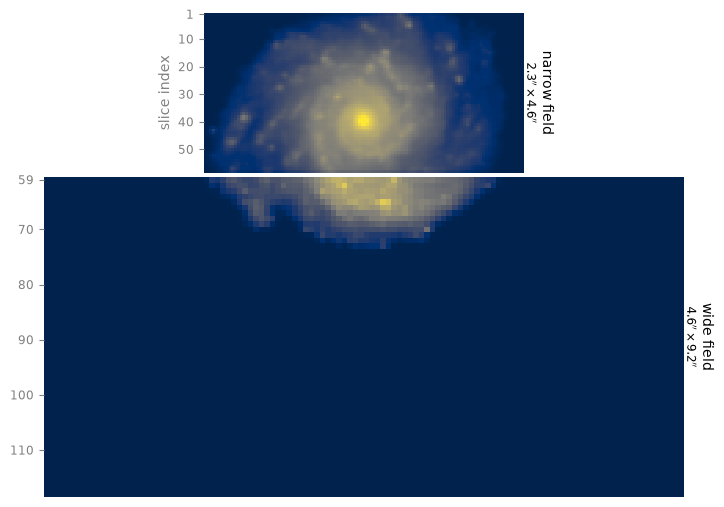

In [10]:
galaxy = slicersim.LazuliGalaxy(redshift=0.5, model="ngc0628", position=(0, -10))

(cube_narrow, _), (cube_wide, _) = galaxy.get_cube(which="both", switch_off=SKY)
fig = galaxy.show_cube((cube_narrow, cube_wide), lbda_range=[6000, 9000])

**Where `Galaxy` differ from other targets**

Its spectrum is extracted within an **aperture**, by default 1 arcsec around the galaxy
center. Everything else works as for any target: `setup_to_snr()`, `get_spectrum()`,
`get_variance_contribution()`... (extractions are detailed in notebook 08).

{'aperture': '1-arcsec', 'aperture__position': 'host'}


{'nmd': (62, 8, 0), 'nramps': 1} SNR=10.7 exposure time: 23 min


[Text(0.5, 0, 'wavelength [Å]'),
 Text(0, 0.5, 'flux [erg/s/cm²/Å]'),
 Text(0.5, 1.0, 'NGC 0628 at z=0.5, 1 arcsec aperture')]

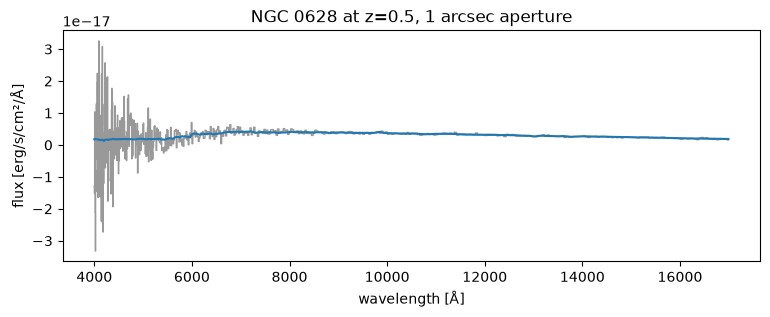

In [11]:
print(galaxy.get_properties(["aperture", "aperture__position"]))
config, snr = galaxy.setup_to_snr(10, **snr_range)
print(config, f"SNR={snr:.1f}", f"exposure time: {galaxy.get_exposure_time() / 60:.0f} min")

lbda, flux, variance = galaxy.get_spectrum(unit="flambda")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(lbda, flux, color="0.6", lw=1, ds="steps-mid")
ax.plot(lbda, galaxy.get_spectrum(unit="flambda", incl_error=False)[1], color="C0")
ax.set(xlabel="wavelength [Å]", ylabel="flux [erg/s/cm²/Å]", title="NGC 0628 at z=0.5, 1 arcsec aperture")

***
## Recap

| what | how |
|---|---|
| SN in a host | `LazuliSupernova(redshift, host="ngc0628")`, `host="sersic:bb-5000"` or `host={"refmodel": ..., ...}` |
| host defaults | `slicersim.scene.host.get_host_config(modelname)` |
| change the host | `change_properties(host__position=..., host__magabs=..., host__r_kpc=...)` |
| move the SN | `change_properties(pointsource__position=...)` |
| redshift | `change_properties(redshift=z)`: SN and host together |
| galaxy alone | `LazuliGalaxy(redshift, model="ngc0628")` |
| images | `get_cube(which="both", switch_off=["background", "thermal"])`, `show_cube()` |

**Next:** [08 — Spectrum extraction](08_spectrum_extraction.ipynb)